In [19]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

In [20]:
eV = 1.602176e-12
mphi = 30.
mpl.rcParams['figure.dpi'] = 500

In [21]:
scenarios = ["B0-05-d", "B1-1-d", "B1-1-h", "B1-1-mc", "B2-60-d"]
shocks = ['RS', 'FS']

In [22]:
distributions = {}

for sc in scenarios:
    distributions[sc] = {}
    for shock in shocks:

        distributions[sc][shock] = {}

        file = f"../../../output/diste_{sc}_{shock}.dat"
        df = pd.read_csv(file, delim_whitespace=True, header=None)

        distributions[sc][shock]["angle"] = df.iloc[:, 0] * 180.0 / np.pi
        distributions[sc][shock]["E_e"]   = df.iloc[:, 1]
        distributions[sc][shock]["diste"] = df.iloc[:, 2] * 4. * mphi
        

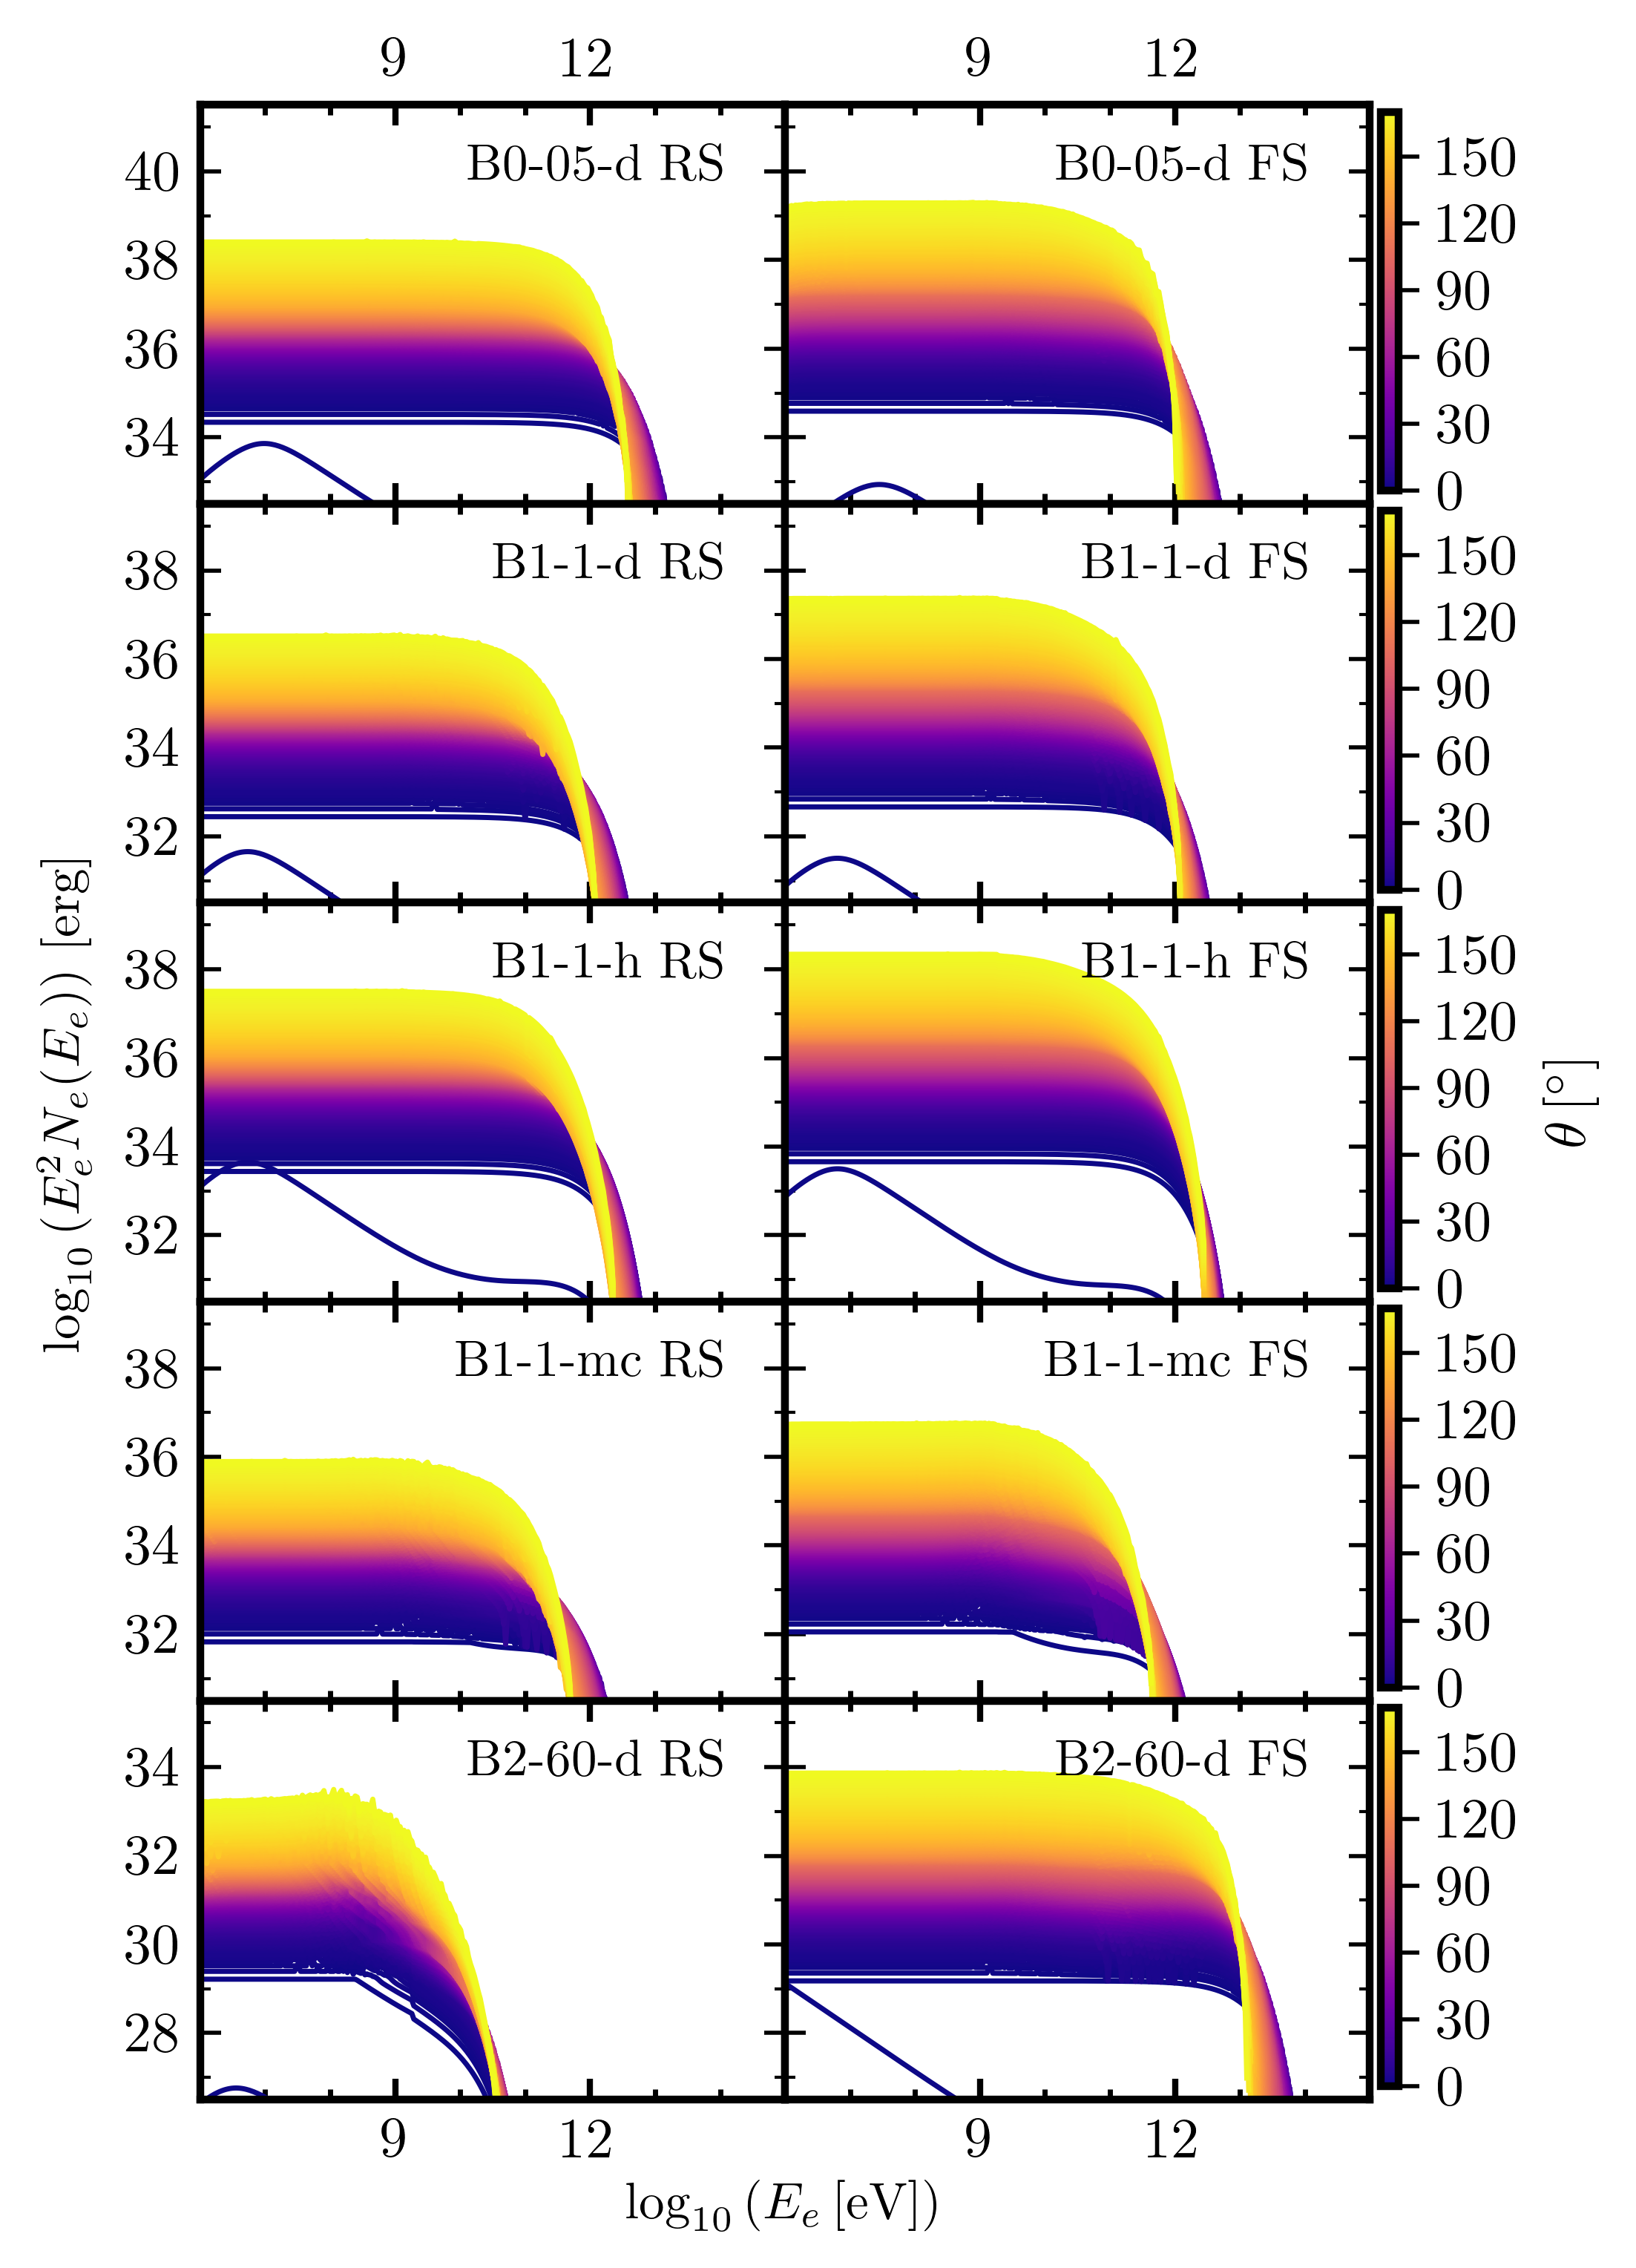

In [23]:
fig, ax = plt.subplots(
    5, 2,
    figsize=(2*text_width/3., 5.*0.7*text_width/3.),
    sharex=True,
    sharey=False
)

plt.subplots_adjust(wspace=0.0, hspace=0.0)

cmap = cm.plasma

for i, sc in enumerate(scenarios):
    for j, shock in enumerate(shocks):

        axi = ax[i][j]
        d = distributions[sc][shock]

        theta = d["angle"]

        norm = mcolors.Normalize(vmin=min(theta), vmax=max(theta))
        
        for cn in np.unique(theta):

            val = (d["E_e"] * eV)**2 * d["diste"]
            mask = (theta == cn) & (val > 0)
            idx = np.where(mask)[0]

            if len(idx) > 1:
                axi.plot(
                    np.log10(d["E_e"])[idx[1:]],
                    np.log10(val[idx[1:]]),
                    color=cmap(norm(cn)),
                    linewidth=1.
                )

        axi.annotate(
            f"{sc} {shock}",
            xy=(0.9, 0.9),
            xycoords="axes fraction",
            ha="right", va="top",
        )

        axi.set_xlim(6, 15)
        axi.set_xticks([9, 12])
        axi.set_xticks([7, 8, 10, 11, 13, 14], minor=True)

        axi.tick_params(
            axis="both", which="both",
            top=True, bottom=True,
            left=True, right=True,
            direction="in"
        )

        if i == len(scenarios)-1:
            axi.set_ylim(26.5, 35.5)
            axi.set_yticks([28, 30, 32, 34])
            axi.set_yticks([27, 29, 31, 33, 35], minor=True)
        elif i == 0:
            axi.set_ylim(32.5, 41.5)
            axi.set_yticks([34, 36, 38, 40])
            axi.set_yticks([33, 35, 37, 39, 41], minor=True)
        else:
            axi.set_ylim(30.5, 39.5)
            axi.set_yticks([32, 34, 36, 38])
            axi.set_yticks([31, 33, 35, 37, 39], minor=True)

        axi.xaxis.set_minor_formatter(NullFormatter())
        axi.yaxis.set_minor_formatter(NullFormatter())
        
        if j == 1:
            axi.tick_params(axis='y', labelleft=False)

        #axi.legend(frameon=False)
        
        # Hide intermediate labels
        if i == 0:
            axi.tick_params(axis='x', labeltop=True, labelbottom=False)
            axi.xaxis.set_ticks_position('both')
        elif i == len(scenarios)-1:
            axi.tick_params(axis='x', labeltop=False, labelbottom=True)
            axi.xaxis.set_ticks_position('both')
        else:
            axi.tick_params(axis='x', labeltop=False, labelbottom=False)
            
    # Colour bars for each row
    pos = ax[i,1].get_position()

    cax = fig.add_axes([
        pos.x1 + 0.007,
        pos.y0+0.005,
        0.012,
        0.95*pos.height
    ])

    sm = plt.cm.ScalarMappable(
        cmap=cmap,
        norm=mcolors.Normalize(vmin=0, vmax=170)
    )
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        cax=cax
    )

    cbar.set_ticks([0,30,60,90,120,150])

    # Central bar
    if i == len(scenarios)//2:
        cbar.set_label(r'$\theta\,[^\circ]$')

# =========================
# Global labels
# =========================
sp = fig.subplotpars
xmid = (sp.left + sp.right) / 2
ymid = (sp.bottom + sp.top) / 2

fig.text(
    sp.left - 0.09, ymid,
    r'$\log_{10}\,(E_e^2 N_e(E_e))$ [erg]',
    ha='center', va='center',
    rotation='vertical'
)

fig.text(
    xmid, sp.bottom - 0.04,
    r'$\log_{10}\,(E_e \, [{\rm eV}])$',
    ha='center', va='center'
)


plt.show()


In [25]:
#fig.savefig('diste_HVSs.pdf', bbox_inches='tight', pad_inches = 0.01)